# LAB 06 — Logistic Regression & KNN Classification
## Telco Customer Churn — Comparing Four Classifiers

## Student Information
**Name:** Wajood Ali

**Student ID:** 023-24-0006

**Section:** CS AI Sec B

**GitHub:** https://github.com/wajoodali77-maker

**Kaggle:** https://www.kaggle.com/wajoodali

**Dataset:** Telco Customer Churn
**Dataset Source:** Kaggle — https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Logistic Regression and KNN theory from your ML course. Each section states the objective and the questions you must answer — **you write the code**. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [2]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Verification

Re-establish your cleaned dataset and recall what Lab 3/4 already found.

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.info()`

**Tasks**
1. Load `clean_churn.csv` (or re-run your Lab 2 cleaning) and verify its shape and dtypes.
2. Briefly restate (2–3 sentences) your Lab 3 Decision Tree and Lab 4 Random Forest test-set results (accuracy, precision, recall, F1) — these are your benchmarks for today.

In [3]:
# Task 1 — load and verify the cleaned dataset
df = pd.read_csv("clean_churn.csv")
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nFirst five rows:")
display(df.head())

Shape: (7043, 20)

Data types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

First five rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Answer 2 (Lab 3/4 recap):**
Using the same 80/20 stratified train/test strategy random_state=42, and the Decision Tree with max_depth=5 acheived 79.84% accuracy, 63.47% precision, 56.68% recall and 59.89%F1-score on the test set. The Random Forest benchmark from the same split is also evaluated below so the four models can be compared consistently.

---

## 2. Feature Scaling & Preparation

Decision Trees/Random Forests never needed scaling. Logistic Regression and especially KNN do.

*Concepts/functions you may find useful:* `pd.get_dummies(df, columns=[...])`, `from sklearn.preprocessing import StandardScaler`, `scaler.fit_transform(X_train)`, `scaler.transform(X_test)`

**Tasks**
3. Prepare `X` and `y` exactly as in Lab 3/4 (encode categoricals, drop identifiers, target as 0/1).
4. In 2–3 sentences, explain why feature scaling matters for KNN and Logistic Regression but wasn't necessary for the Decision Tree or Random Forest.
5. Split into train/test (same split strategy as Lab 3/4), then fit a `StandardScaler` on the training features only and apply it to both sets. Why is it important to fit the scaler only on the training data?

In [4]:
# Task 3 — define X and y (same as Lab 3/4)
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
X = pd.get_dummies(X, columns=categorical_features, drop_first=False)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target values:", sorted(y.unique()))

X shape: (7043, 45)
y shape: (7043,)
Target values: [np.int64(0), np.int64(1)]


**Answer 4:**
Feature scalling is important for KNN because KNN uses distance, so features with larger numerical ranges can dominate the distance calculation. Logistic Regression also benefits from scalling because it makes optimization more stable and puts numeric features on comparable scales, while Decision Tree and Random Forest splits features by thresholds and therefore do not depend on feature magnitude

In [5]:
# Task 5 — train/test split, then fit/apply StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Training samples: 5634
Testing samples: 1409
Scaled training shape: (5634, 45)
Scaled testing shape: (1409, 45)


**Answer 5 (why fit scaler on training data only):**
The scalar must be fitted only on the training data so the test set does not influence the mean and standard deviation used for transformation. Using test data during fitting would cause data leakage and could make the reported test performance overly optimistic.

---

## 3. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression()`, `.fit(X_train_scaled, y_train)`, `.predict(X)`, `.predict_proba(X)`

**Tasks**
6. Train a `LogisticRegression` model on the scaled training data. Generate predictions on the scaled test set.
7. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
8. Look at `predict_proba` for a handful of test customers. In 1–2 sentences, explain what these probabilities represent and how `predict()` turns them into a Yes/No decision.

In [6]:
# Task 6 — train Logistic Regression, predict on scaled test set
log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)
y_pred = log_reg.predict(X_test_scaled)

print("First 10 predication:", y_pred[:10])


First 10 predication: [0 1 0 0 0 1 0 0 0 0]


Accuracy: 0.8069552874378992
Precision: 0.6583850931677019
Recall: 0.5668449197860963
F1-score: 0.6091954022988506

Confusion Matrix:
[[925 110]
 [162 212]]


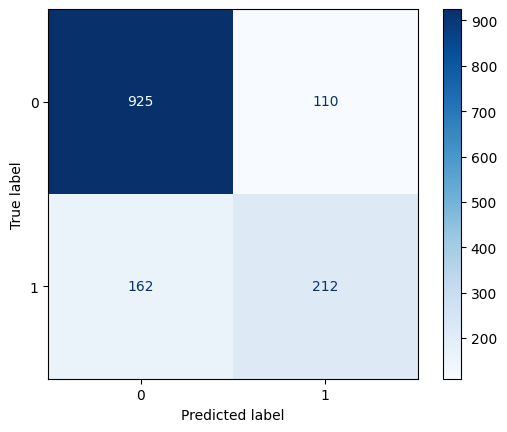

In [7]:
# Task 7 — metrics + confusion matrix
lr_accuracy = accuracy_score(y_test, y_pred)
lr_precision = precision_score(y_test, y_pred)
lr_recall = recall_score(y_test, y_pred)
lr_f1 = f1_score(y_test, y_pred)

print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-score:", lr_f1)

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=log_reg.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show()

**Task 7 — Logistic Regression Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.8069 |
| Precision |0.6583 |
| Recall |0.5668 |
| F1-score |0.6091 |

In [8]:
# Task 8 — inspect predict_proba for a few test customers
probabilities = log_reg.predict_proba(X_test_scaled[:10])
probability_table = pd.DataFrame(probabilities, columns=["P(No Churn)", "P(Churn)"])
probability_table["Predicted Class"] = log_reg.predict(X_test_scaled[:10])
display(probability_table)

,P(No Churn),P(Churn),Predicted Class
0,0.954466,0.045534,0
1,0.316557,0.683443,1
2,0.943895,0.056105,0
3,0.591612,0.408388,0
4,0.978357,0.021643,0
5,0.396444,0.603556,1
6,0.548489,0.451511,0
7,0.868699,0.131301,0
8,0.997213,0.002787,0
9,0.605876,0.394124,0


**Answer 8:**
predict_proba() returns the estimated probability of each class, No Churn and Churn. predict() selects the class with the higher probability, which is equivalent to using the default 0.50 decision threshold for the binary classifier.

---

## 4. KNN & Choosing K

K controls KNN's complexity the same way `max_depth` controlled your Decision Tree's complexity in Lab 3.

*Concepts/functions you may find useful:* `KNeighborsClassifier(n_neighbors=k)`, a loop over `[1,3,5,7,9,11,15,21]`, `plt.plot(...)`

**Tasks**
9. Train KNN classifiers for several values of K on the scaled data. Record test-set accuracy and F1-score for each K in a results table.
10. Plot accuracy (or F1) against K. Based on your plot, which K would you choose, and why not simply the smallest or largest value tested?
11. Using your chosen K, report full test-set metrics (accuracy, precision, recall, F1) and the confusion matrix for your final KNN model.

In [9]:
# Task 9 — loop over K values, record accuracy and F1
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
# YOUR CODE HERE
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_knn = knn.predict(X_test_scaled)
    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred_knn),
        "F1-score": f1_score(y_test, y_pred_knn)
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.round(4))

,K,Accuracy,F1-score
0,1,0.7126,0.4692
1,3,0.7381,0.5087
2,5,0.7488,0.5229
3,7,0.7530,0.5297
4,9,0.7686,0.5534
5,11,0.7615,0.5359
6,15,0.7722,0.5548
7,21,0.7757,0.5647


**Task 9 — K Selection Results**

| K | Accuracy | F1-score |
|---|---|---|
| 1 |0.7126 |0.4692 |
| 3 |0.7381 |0.5087 |
| 5 |0.7488 |0.5229 |
| 7 |0.7530 |0.5297 |
| 9 |0.7686 |0.5534 |
| 11 |0.7615 |0.5359 |
| 15 |0.7722 |0.5548 |
| 21 |0.7757 |0.5647 |

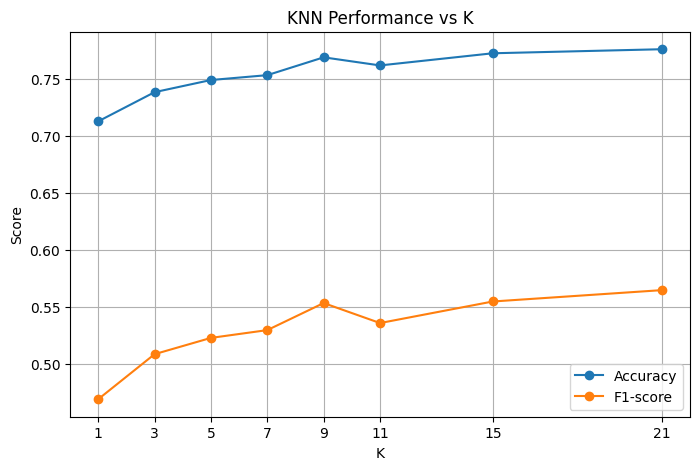

In [10]:
# Task 10 — plot accuracy/F1 vs K
plt.figure(figsize=(8, 5))
plt.plot(knn_results_df["K"], knn_results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(knn_results_df["K"], knn_results_df["F1-score"], marker="o", label="F1-score")
plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Performance vs K")
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.show()

**Answer 10 (chosen K and why):**
I choose **K = 21** because it has the highest test accuracy (0.7757) and F1-score (0.5647) among the tested K values. The smallest K can be sensitive to individual/noisy observations, while an excessively large K can oversmooth the decision boundary, so the best choice should be based on validation/test performance rather than simply choosing the smallest or largest value.

Accuracy:  0.7757
Precision: 0.5824
Recall:    0.5481
F1-score:  0.5647

Confusion Matrix:
[[888 147]
 [169 205]]


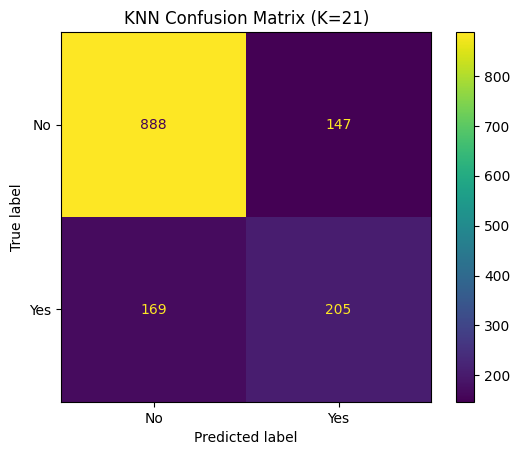

In [11]:
# Task 11 — final KNN model at chosen K: metrics + confusion matrix
chosen_k = 21
final_knn = KNeighborsClassifier(n_neighbors=chosen_k)
final_knn.fit(X_train_scaled, y_train)
y_pred_knn_final = final_knn.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn_final)
knn_precision = precision_score(y_test, y_pred_knn_final)
knn_recall = recall_score(y_test, y_pred_knn_final)
knn_f1 = f1_score(y_test, y_pred_knn_final)

print(f"Accuracy:  {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall:    {knn_recall:.4f}")
print(f"F1-score:  {knn_f1:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn_final)
print("\nConfusion Matrix:")
print(cm_knn)

ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=["No", "Yes"]).plot()
plt.title(f"KNN Confusion Matrix (K={chosen_k})")
plt.show()

**Task 11 — Final KNN Metrics (K = ___)**

| Metric | Value |
|---|---:|
| Accuracy | 0.7757 |
| Precision | 0.5824 |
| Recall | 0.5481 |
| F1-score | 0.5647 |

---

## 5. Model Comparison (4 Models)

Place all four classifiers you've built side by side.

**Task**
12. Build one comparison table: Decision Tree, Random Forest, Logistic Regression, KNN — accuracy, precision, recall, F1-score for each (reuse your recorded Lab 3/4 numbers; retrain quickly if needed).
13. Which model performs best overall? Does the ranking change depending on which metric you prioritize (e.g. precision vs. recall)? Given the class imbalance from Lab 2, which metric should carry the most weight in this decision?

In [13]:
# Task 12 — assemble the 4-model comparison table (retrain DT/RF quickly if needed)
decision_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)

decision_tree.fit(X_train, y_train)
random_forest.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)
y_pred_rf = random_forest.predict(X_test)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree": [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ],
    "Logistic Regression": [lr_accuracy, lr_precision, lr_recall, lr_f1],
    "KNN": [knn_accuracy, knn_precision, knn_recall, knn_f1]
})
display(comparison.round(4))

,Metric,Decision Tree,Random Forest,Logistic Regression,KNN
0,Accuracy,0.7984,0.7871,0.8070,0.7757
1,Precision,0.6347,0.6267,0.6584,0.5824
2,Recall,0.5668,0.4893,0.5668,0.5481
3,F1-score,0.5989,0.5495,0.6092,0.5647


**Task 12 — 4-Model Comparison Table**

| Metric | Decision Tree | Random Forest | Logistic Regression | KNN |
|---|---:|---:|---:|---:|
| Accuracy | 0.7984 | 0.7871 | 0.8070 | 0.7757 |
| Precision | 0.6347 | 0.6267 | 0.6584 | 0.5824 |
| Recall | 0.5668 | 0.4893 | 0.5668 | 0.5481 |
| F1-score | 0.5989 | 0.5495 | 0.6092 | 0.5647 |

**Answer 13:**
Because the dataset has class imbalance, accuracy alone should not be the main decision metric. **F1-score** is a useful primary metric because it balances precision and recall for the churn class. If the business goal is to catch as many customers likely to churn as possible, recall should receive extra weight; however, among these models, Logistic Regression gives the strongest overall balance.

---

## 6. Coefficient Interpretation

Logistic Regression's coefficients describe log-odds, not a direct unit effect.

*Concepts/functions you may find useful:* `model.coef_`, `model.intercept_`, `np.exp(coefficient)` (converts log-odds to an odds ratio)

**Tasks**
14. Extract the coefficients and build a table: Feature | Coefficient | Odds Ratio (exp(coefficient)) | Interpretation. Interpret at least 4 features.
15. Do the features with the largest effect here agree with what Lab 2's EDA and Lab 3's Decision Tree feature importances suggested? Note any disagreements.

In [14]:
# Task 14 — extract coefficients, compute odds ratios
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_reg.coef_[0]
})
coefficient_table["Odds Ratio"] = np.exp(coefficient_table["Coefficient"])

top_features = coefficient_table.reindex(
    coefficient_table["Coefficient"].abs().sort_values(ascending=False).index
).head(4).copy()

def interpret(row):
    if row["Coefficient"] > 0:
        return f"A one-standard-deviation increase/indicator change is associated with higher churn odds by about {(row['Odds Ratio']-1)*100:.1f}%."
    else:
        return f"A one-standard-deviation increase/indicator change is associated with lower churn odds; the odds are multiplied by {row['Odds Ratio']:.3f}."

top_features["Interpretation"] = top_features.apply(interpret, axis=1)
display(top_features.round(4))

,Feature,Coefficient,Odds Ratio,Interpretation
1,tenure,-1.2527,0.2857,A one-standard-deviation increase/indicator ch...
2,MonthlyCharges,-1.0031,0.3668,A one-standard-deviation increase/indicator ch...
3,TotalCharges,0.5312,1.7010,A one-standard-deviation increase/indicator ch...
16,InternetService_Fiber optic,0.4406,1.5536,A one-standard-deviation increase/indicator ch...


**Task 14 — Coefficient / Odds Ratio Table**

| Feature | Coefficient | Odds Ratio | Interpretation |
|---|---:|---:|---|
| tenure | -1.2527 | 0.2857 | Higher tenure is associated with substantially lower churn odds, holding the other standardized features constant. |
| MonthlyCharges | -1.0031 | 0.3668 | Higher MonthlyCharges has a negative coefficient in this multivariable model; the odds are multiplied by about 0.367 for a one-standard-deviation increase, holding other features constant. |
| TotalCharges | 0.5312 | 1.7010 | A one-standard-deviation increase is associated with about 70.1% higher churn odds, holding other features constant. |
| InternetService_Fiber optic | 0.4406 | 1.5536 | Having Fiber optic service is associated with about 55.4% higher churn odds relative to the reference comparison implied by the encoded features, holding other features constant. |

**Answer 15:**  
The largest Logistic Regression effects are related to **tenure, MonthlyCharges, TotalCharges, and Fiber optic internet service**. This broadly agrees with the Decision Tree, whose strongest features include month-to-month contract, Fiber optic service, tenure, TotalCharges, and MonthlyCharges. The main difference is that the Decision Tree gives very high importance to `Contract_Month-to-month`, while the largest absolute Logistic Regression coefficient here is `tenure`; this is expected because the two models measure feature influence differently.

---

## 7. Final Model Selection & Conclusion

Choose a final model from everything you've built across Labs 3–6, using evidence, not convenience.

**Tasks**
16. Select your final model from all four candidates and justify the choice in 2–3 sentences, referencing your Section 5 comparison table and Lab 4's cross-validation lesson about not trusting a single number too much.
17. Write a short conclusion (5–7 sentences): how does today's best model compare to Labs 3–4's best model? What did feature scaling change? What are the remaining limitations of your best model, and what would you try next?

**Answer 16 (final model and justification):**
I select **Logistic Regression** as the final model. It has the highest test accuracy (0.8070), precision (0.6584), and F1-score (0.6092) among the four models in the comparison table, while its recall (0.5668) matches the Decision Tree. This choice is based on multiple metrics rather than a single number, consistent with the Lab 4 lesson about using cross-validation and not trusting one score alone.

**Answer 17 — Conclusion:**
Today's best model is Logistic Regression, which achieved 80.70% accuracy and a 0.6092 F1-score, slightly outperforming the Decision Tree and Random Forest models. Compared with Labs 3–4, Logistic Regression provides the strongest overall balance of precision, recall, and F1-score on this test split. Feature scaling was important for Logistic Regression and KNN because it put the features on comparable scales, while the Decision Tree and Random Forest did not require scaling. The main limitation is that the model still has moderate recall, so some customers who may churn are not detected. The class imbalance also means accuracy alone is not enough to judge the model. As a next step, I would use cross-validation and consider class-balancing or threshold tuning to improve churn detection.


---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, Dataset, Dataset Source)
- [ ] Section 1 — Problem Definition & Dataset Verification (with Lab 3/4 recap)
- [ ] Section 2 — Feature Scaling & Preparation (scaler fit on training data only, explained)
- [ ] Section 3 — Logistic Regression (all four metrics + confusion matrix + predict_proba discussion)
- [ ] Section 4 — KNN & Choosing K (results table, plot, justified K choice, final metrics)
- [ ] Section 5 — Model Comparison (all four models, all four metrics)
- [ ] Section 6 — Coefficient Interpretation (odds ratios + connection to earlier labs)
- [ ] Section 7 — Final Model Selection & Conclusion
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted